<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [63]:
import random

In [64]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [65]:
len(l)

10000

In [66]:
l[:5]

[5, 11, 6, 11, 9]

In [67]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0287
3     0.0545
4     0.0830
5     0.1147
6     0.1419
7     0.1580
8     0.1440
9     0.1078
10    0.0818
11    0.0576
12    0.0280
Name: count, dtype: float64


<Axes: >

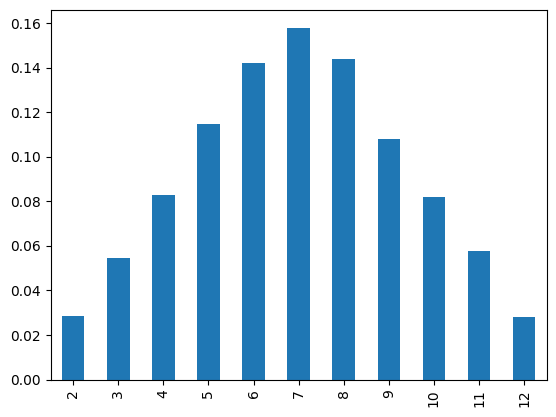

In [68]:
s.plot(kind='bar')

<Axes: >

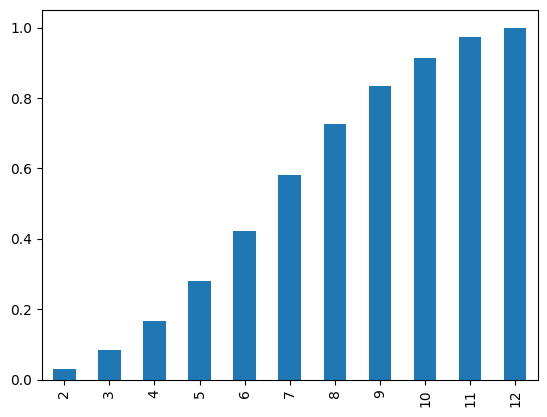

In [69]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [70]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[55.26897886 39.00460604 45.8625471  58.93067955 45.71122322 56.13271606
 55.82830664 56.40206195 40.9605885  53.50155771 51.01350941 41.7291441
 49.90497229 50.26326267 55.01810989 47.42686373 36.51756648 52.19232287
 49.85211385 41.73643531 51.77548948 47.52851732 42.26456294 48.69719965
 46.56583429 49.02501812 41.45425864 38.01349968 49.61063018 63.21974042
 44.78626212 44.66876421 53.33603651 49.5393446  60.06796804 48.09969621
 44.58404854 47.02740038 51.10262895 54.73061161 60.50363279 49.68108881
 46.2983422  53.08760649 51.29115502 46.40443562 45.79773647 45.68137782
 45.22988235 54.11787378 47.52788746 56.86211475 51.2310321  48.49589019
 52.1526539  45.00186551 48.64316524 42.6828174  48.67195955 46.82190097
 46.92462905 54.49658557 53.03513402 51.93932382 48.96345499 46.72138694
 48.94052349 55.53009508 48.59287968 50.9284515  51.28803942 47.57221269
 41.30263729 46.12259544 51.39457182 56.96245692 57.11499844 51.33752923
 48.5262267  48.97819904 41.62210086 43.49006311 50.

In [71]:
sample.mean()

np.float64(49.69592952876751)

(array([  4.,  19.,  63., 134., 183., 253., 199., 100.,  34.,  11.]),
 array([33.58420181, 36.61972487, 39.65524792, 42.69077098, 45.72629404,
        48.76181709, 51.79734015, 54.8328632 , 57.86838626, 60.90390932,
        63.93943237]),
 <BarContainer object of 10 artists>)

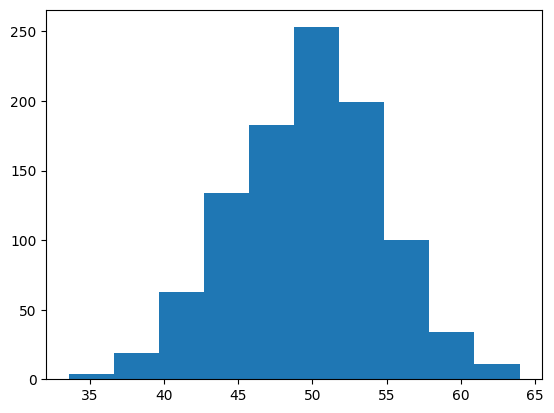

In [72]:
plt.hist(sample,bins=10)

In [73]:
sample_mean=sample.mean()
sample_std=sample.std()

In [74]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [75]:
sample.min()

np.float64(33.584201812017824)

In [76]:
sample.max()

np.float64(63.93943237168835)

In [77]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [78]:
probabilities=[dist.pdf(value) for value in values]

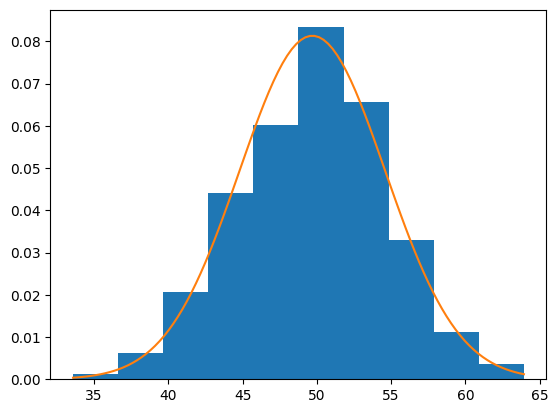

In [79]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_1683/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

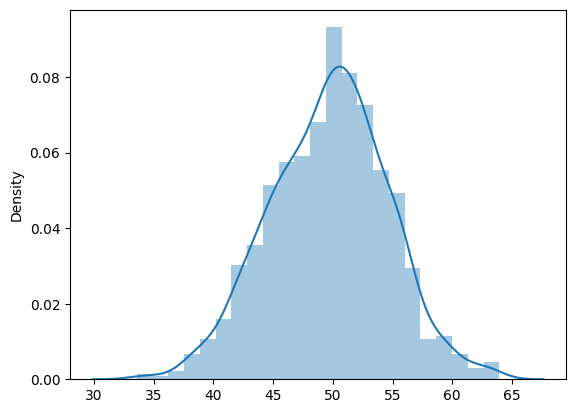

In [80]:
import seaborn as sns
sns.distplot(sample)

KDE

In [81]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [82]:
sample

array([21.1332363 , 18.7741493 , 24.71879694, 22.46982744, 21.6998411 ,
       17.96299758, 22.46203953,  9.32408894, 21.89032567, 22.36780031,
       21.24723816, 20.81894033,  5.46813202, 17.23848481, 26.938112  ,
       25.16340205, 18.99052613, 16.55307376, 29.23196273, 18.17751341,
       22.81671208, 17.60068487, 18.31772051, 17.42894797, 23.5913658 ,
       18.82221928, 20.34998957, 15.17916056, 23.84837989, 16.61387033,
       20.460145  , 19.55873642, 36.79637684, 13.5654097 , 20.75135013,
       21.33868146, 16.48810577,  9.97519518, 20.39507939, 19.43192551,
       28.65632612, 31.76799836, 17.40385234, 23.6458668 , 14.68813309,
       16.97470843, 19.44884839, 14.20498094, 25.0628902 , 20.5339188 ,
       21.38291343, 26.4697012 , 21.5380073 , 16.25114209, 20.01803416,
        9.16173415, 24.08421759, 25.02378842, 20.72614168, 24.90027889,
        9.05413754, 26.5812939 , 23.24110113, 24.16577508, 30.66686978,
       15.40778747, 26.63260539, 15.64535648,  9.04571644, 11.70

(array([ 1.,  1.,  1.,  7.,  4.,  1.,  5.,  6.,  9., 12., 15., 17., 23.,
        28., 19., 33., 18., 21., 16., 17., 12., 15.,  8., 11., 11., 11.,
        14., 18., 23., 25., 23., 45., 57., 45., 53., 64., 43., 51., 45.,
        34., 30., 25., 26., 16., 11., 13.,  6.,  2.,  6.,  3.]),
 array([ 5.46813202,  6.44253119,  7.41693036,  8.39132953,  9.3657287 ,
        10.34012787, 11.31452704, 12.28892622, 13.26332539, 14.23772456,
        15.21212373, 16.1865229 , 17.16092207, 18.13532124, 19.10972041,
        20.08411958, 21.05851875, 22.03291792, 23.00731709, 23.98171627,
        24.95611544, 25.93051461, 26.90491378, 27.87931295, 28.85371212,
        29.82811129, 30.80251046, 31.77690963, 32.7513088 , 33.72570797,
        34.70010714, 35.67450631, 36.64890549, 37.62330466, 38.59770383,
        39.572103  , 40.54650217, 41.52090134, 42.49530051, 43.46969968,
        44.44409885, 45.41849802, 46.39289719, 47.36729636, 48.34169554,
        49.31609471, 50.29049388, 51.26489305, 52.23929222,

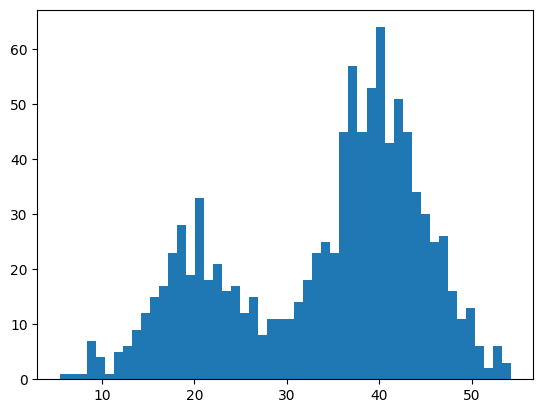

In [83]:
plt.hist(sample,bins=50)

In [84]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [85]:
dataset=sns.load_dataset("iris")

In [86]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

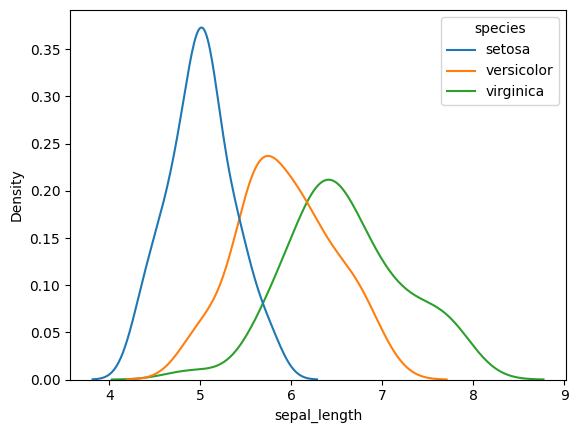

In [87]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

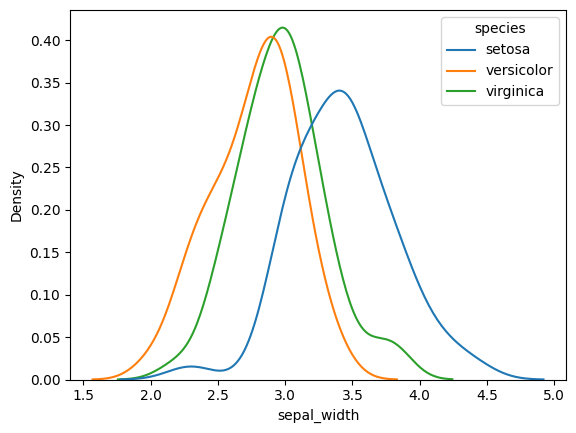

In [88]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

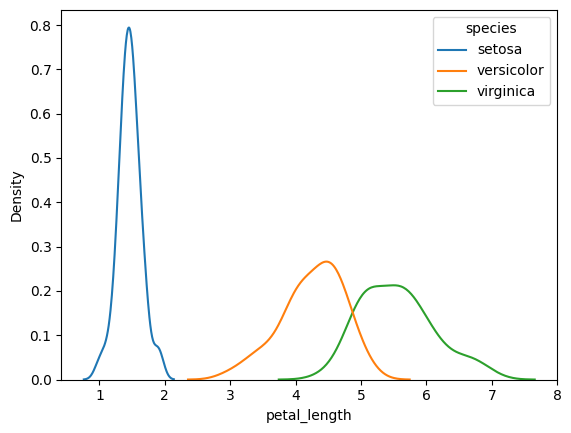

In [89]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

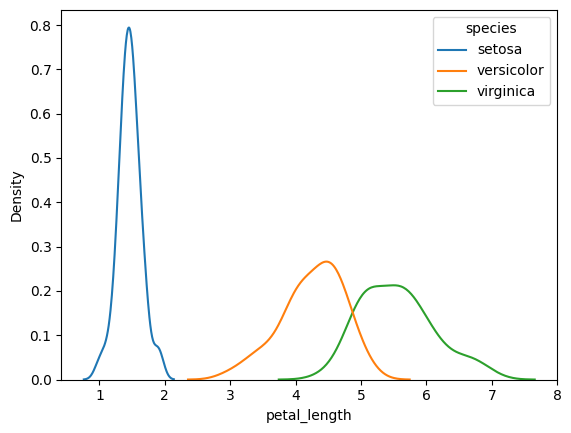

In [90]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [91]:
tips=sns.load_dataset("tips")

In [92]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

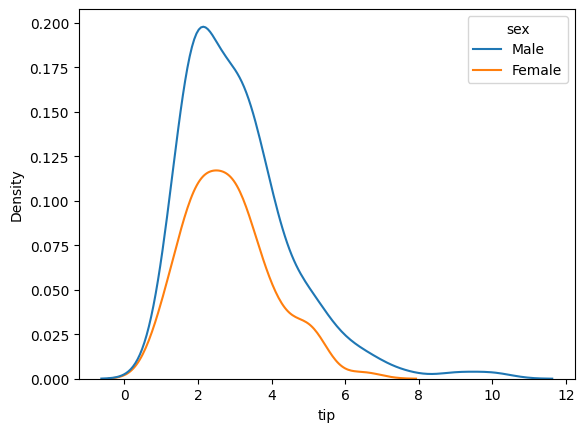

In [93]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

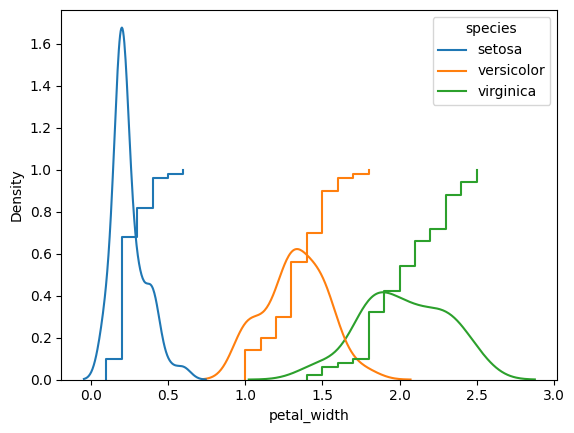

In [94]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [95]:
#contour plots

How to find distribution is normal or not?

In [96]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

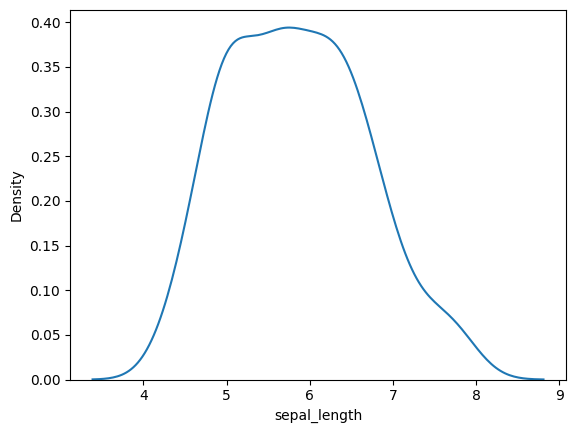

In [97]:
sns.kdeplot(iris["sepal_length"])

In [98]:
temp=sorted(iris['sepal_length'].tolist())

In [99]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [100]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [101]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

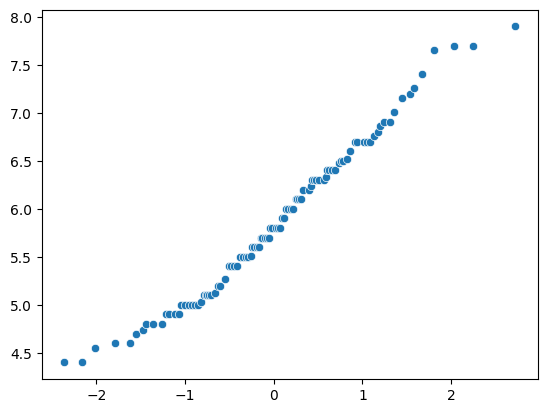

In [102]:
sns.scatterplot(x=x_quant,y=y_quant)

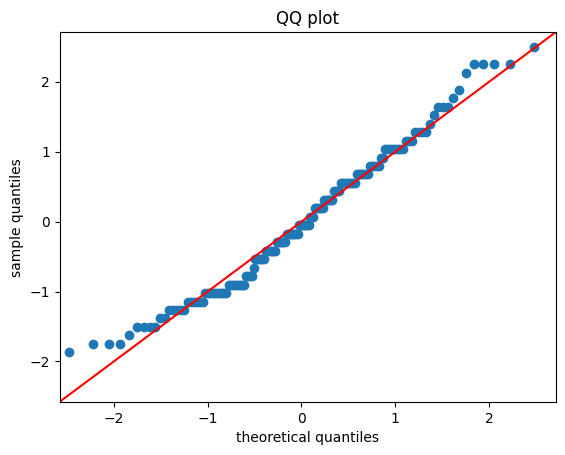

In [103]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [104]:
import scipy.stats as stats

In [105]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([116.,  98., 103., 106., 108., 105.,  87.,  90.,  97.,  90.]),
 array([9.72809649e-04, 1.00856414e-01, 2.00740018e-01, 3.00623623e-01,
        4.00507227e-01, 5.00390831e-01, 6.00274436e-01, 7.00158040e-01,
        8.00041644e-01, 8.99925249e-01, 9.99808853e-01]),
 <BarContainer object of 10 artists>)

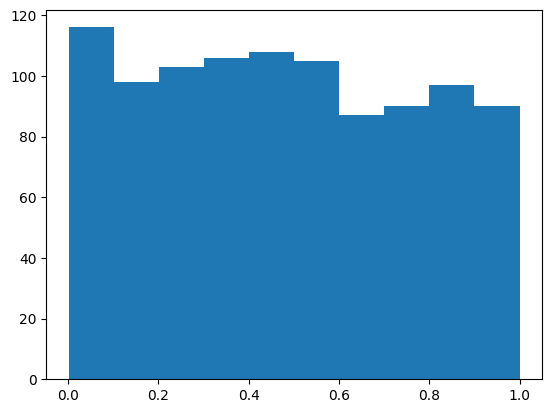

In [106]:
plt.hist(x)

PARETO DISTRIBUTION

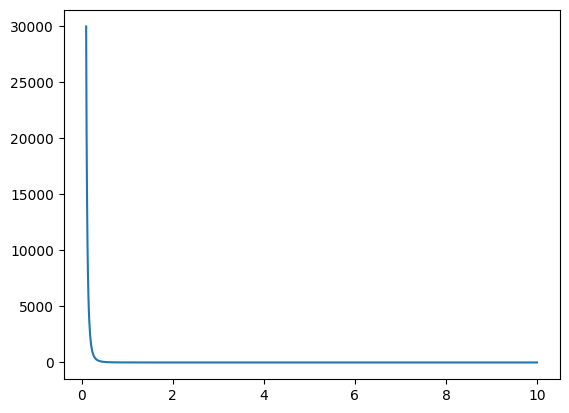

In [107]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

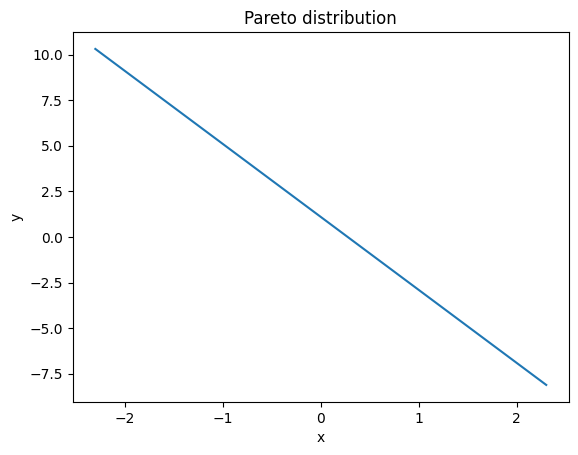

In [108]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [109]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([995.,   3.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   1.]),
 array([  1.00024326,  21.70825492,  42.41626657,  63.12427823,
         83.83228988, 104.54030154, 125.24831319, 145.95632485,
        166.6643365 , 187.37234816, 208.08035981]),
 <BarContainer object of 10 artists>)

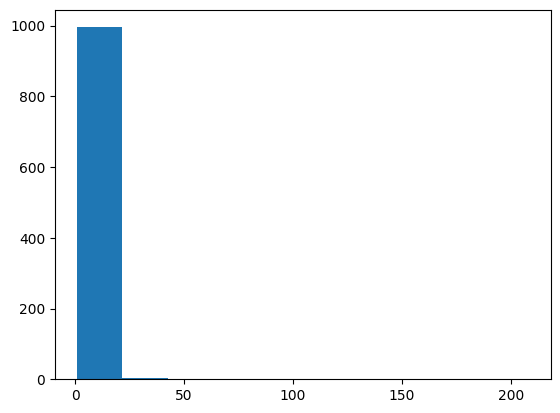

In [110]:
plt.hist(x)

In [111]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

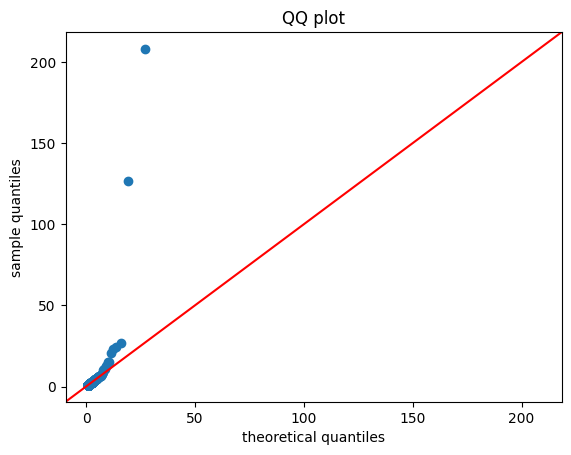

In [112]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [113]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [114]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [115]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [116]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Gaming User,0
Design Capacity,0
Cycle Count,0
CPU Usage,0
GPU Usage,0
Power Consumption,0
Average Temperature,0
Full Charge Capacity,0


In [117]:
x=df.iloc[:,1:5]
y=df.iloc[:,0]

In [118]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

/tmp/ipykernel_1683/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

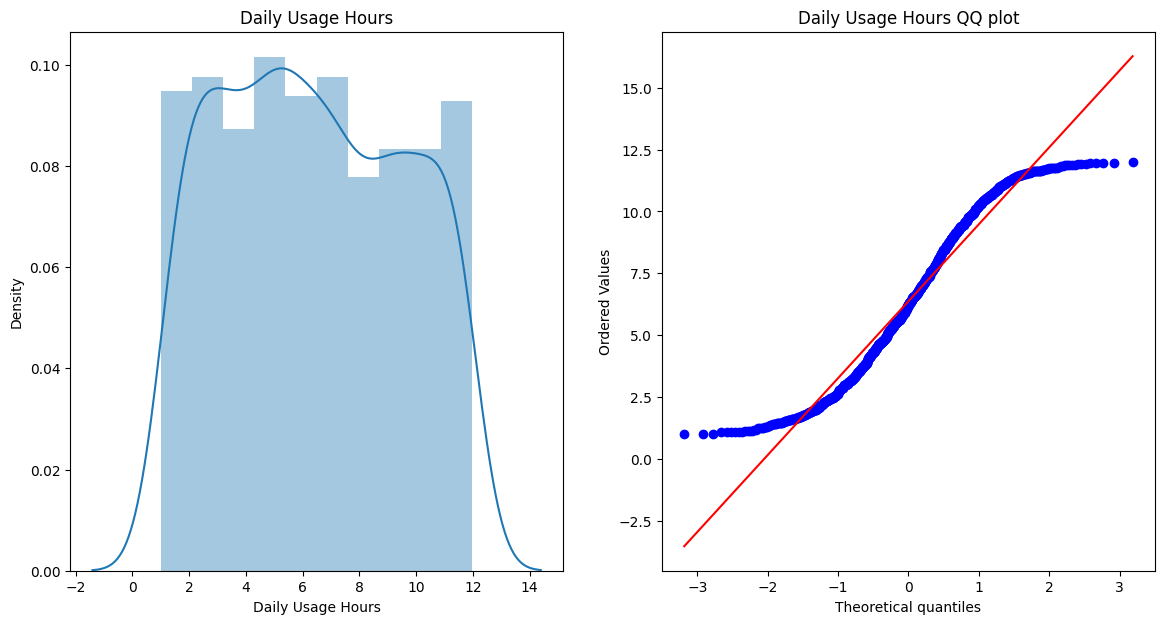

In [119]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

Text(0.5, 1.0, 'Cycle Count QQ plot')

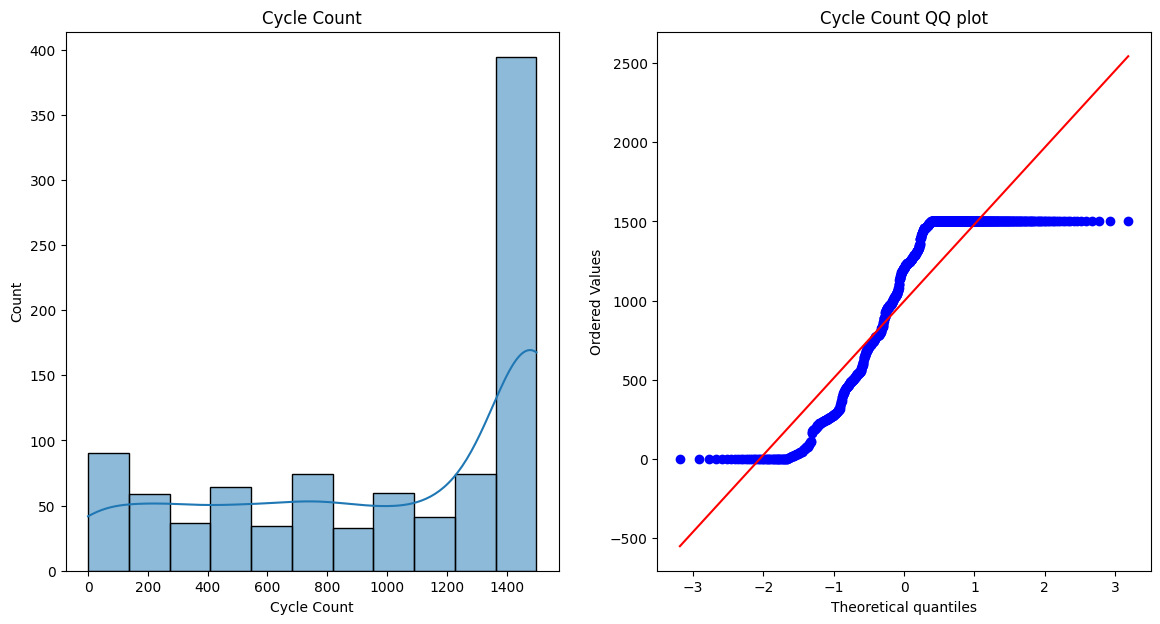

In [152]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.histplot(x_train['Cycle Count'], kde=True)
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")

In [121]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [122]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 4) (1200,)


In [123]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
0           9.797617            0            57884         1267
1           7.101557            0            63824         1500
2          10.085255            0            79414         1500
3           7.946047            0            61142         1153
4           9.628460            0            50956         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Gaming User             2
Design Capacity      1175
Cycle Count           562
dtype: int64


In [124]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [125]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.4583333333333333
Accuracy DT 0.7041666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [126]:
trf=FunctionTransformer(np.log1p)

In [127]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
1053           2.445617     0.000000        11.063007     6.532334
149            2.164608     0.000000        11.180650     6.715383
839            2.514035     0.000000        11.074700     7.313887
1137           2.302305     0.000000        10.882002     5.634790
163            2.514159     0.693147        11.156622     7.313887
...                 ...          ...              ...          ...
1095           1.480119     0.000000        11.017432     7.185387
702            1.736752     0.000000        11.039540     5.252273
452            1.208207     0.000000        10.809283     6.655440
327            1.175109     0.000000        11.016512     2.833213
933            1.753243     0.000000        11.232616     7.313887

[960 rows x 4 columns]
      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
464            1.349866          0.0        11.202916     7.313887
819            2.551880          0.0  

In [128]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.5375
Accuracy DT 0.7166666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[ 5  2  4  5  5  2  5  5  3  7  5  5  5  6  2  5  3  6  8  5  2  4  6  6
  5  6  4  5  7  2  7  7  3  4  6  3  7  6  4  5  7  5  7  5  5  5  5  4
  6  5  4  3  4  6  5  5  4  5  5  6  6  4  8  3  3  6  4  6  3  5  4  5
  3  4  8  3  4  4  6  6  6  3  5  5  6  6  5  5  2  5  6  3  6  5  5  7
  5  5  4  7  6  5  8  6  2  4  8  5  6  4  8  7  8  6  5  4  3  4  6  6
  4  7  6  4  6  5  3  5  5  4  4  4  6  6  6  5  5  5  3  5  4  9  5  5
  6  5  7  5  2  7  5  3  5  3  7  4  7  4  4  5  3  8  2  7  5  4  4  7
  4  2  5  7  6  4  6  2  3  4  6  4  4  7  6  6  5  6  6  3  5  7  5  6
  5  4  7  4  2  4  6  5  6  5  3  4  6  7  6  4  4  7  2  7  4  6  4  4
  8  7  7  5  3  8  5  5  6  7  6  4  1  5  4  5  4  7  5  3  3  7  6  6
  6  5  2  5  6  4  4  7  4  6  6  4  5  6  5  3  6  7  4  4  5  6  7  8
  4  5  4  3  1  8  3  4  2  6  4  6  4  6  1  6  6  6  7  6  6  7  3  3
  3  6  4  4  6  5  3  5  5  6  3  6  6  3  4  5  3  3  5  4  7  6  4  4
  5  4  3  6  6  4  3  5  6  2  6  4  6  6  8  4  2

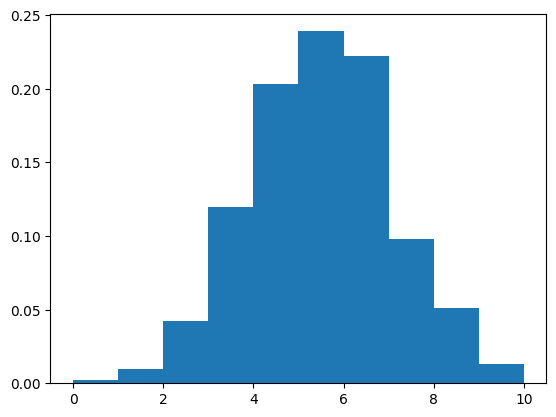

In [129]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [130]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [131]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.49784012, 0.51237933, 0.50768771, ..., 0.50121142, 0.48773804,
       0.51163701])

In [132]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

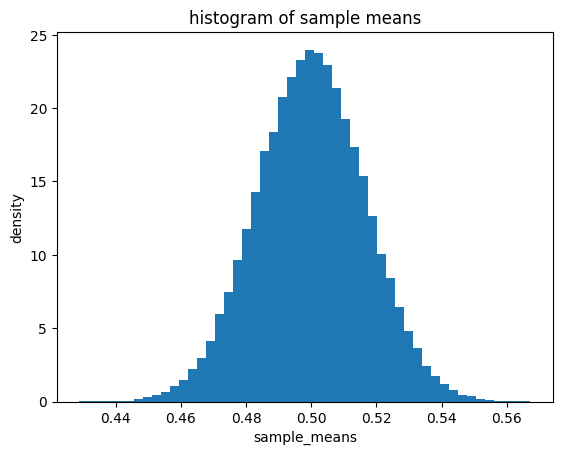

In [133]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [134]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

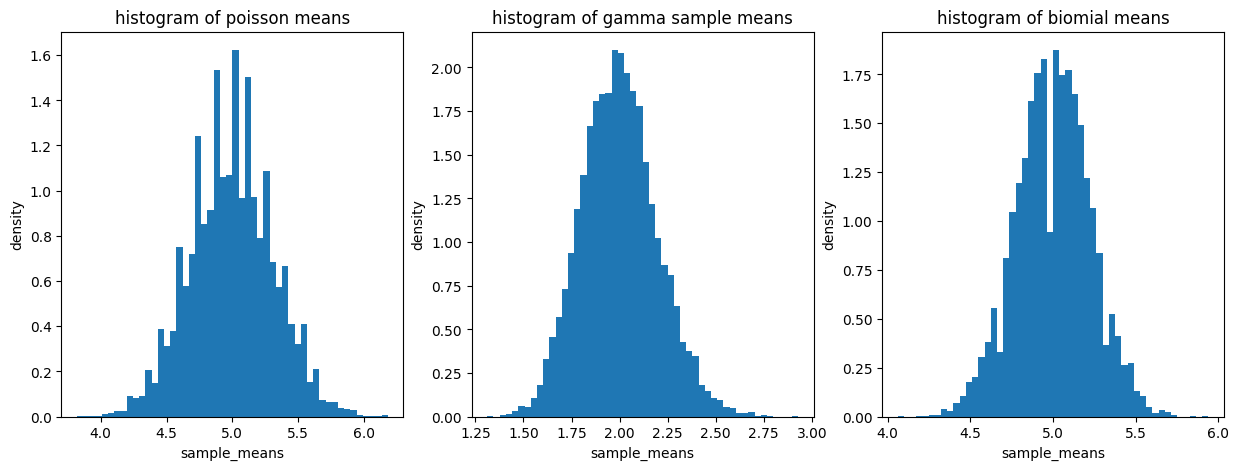

In [135]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [136]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 1.993021426229599
Emperical variance: 0.0673676521014264


CASE STUDY

In [137]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [138]:
battery_csv.shape

(1200, 11)

In [139]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
276,8,2.613646,0,60928,1500,26.609742,19.481644,50.720056,27.879167,45921.411400,75.246943
384,7,2.323999,0,46789,1500,16.141230,7.984009,32.430202,29.022200,30898.131209,64.716046
949,6,2.478768,0,67257,1490,23.048460,9.599892,28.926115,31.287237,52738.985666,77.047091
1180,4,8.028593,0,71502,1041,54.538166,35.795002,64.544203,32.833594,60893.607353,84.788628
642,8,9.043756,0,55778,1500,54.110561,34.485270,69.778606,32.568461,39635.531018,69.639176
...,...,...,...,...,...,...,...,...,...,...,...
424,4,1.076805,0,58895,958,21.785230,12.105607,41.091838,32.815734,48773.718019,82.890215
200,9,1.152483,0,49947,1500,13.332434,12.557384,29.726911,29.870023,32258.335625,62.680051
932,7,11.339168,0,62040,1500,63.693276,39.009847,76.982461,31.702103,46785.863333,75.396673
582,5,9.182957,0,57612,1174,62.997459,42.557838,87.057465,33.440686,45641.115673,80.564637


In [140]:
d['Daily Usage Hours'].mean()

np.float64(6.43507813125098)

<Axes: ylabel='Density'>

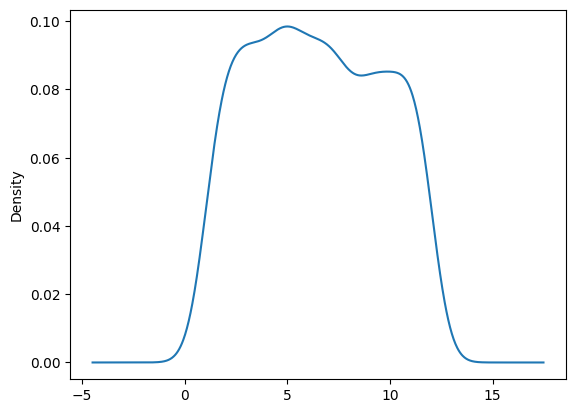

In [141]:
d['Daily Usage Hours'].plot(kind='density')

In [142]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
92,11.917661
668,3.161357
688,2.828809
295,4.442115
1193,6.139871
881,10.727778
480,8.603713
78,4.469001
1161,4.550908
338,9.530558


In [143]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[3.704321867427403,
 3.329204482576615,
 9.400614962853526,
 3.23888361275586,
 2.173830010125897,
 4.469001175927293,
 3.244964272713363,
 7.945135754077143,
 9.043756482821124,
 4.671542567767776,
 4.689087668392087,
 6.52609001969305,
 5.2465602921701935,
 2.31054739195653,
 7.46790792410216,
 1.9873545061617284,
 6.226103747608925,
 11.487431673203044,
 11.25823379576557,
 2.7760361747066407,
 8.565461270023082,
 1.551928853519714,
 9.745126906213176,
 11.081380662270655,
 10.658368641289028,
 1.519163718671169,
 2.319482359040668,
 11.18665515800092,
 11.260282329663443,
 10.43643561869238,
 6.810081879319918,
 11.528483157937757,
 4.9155355081770455,
 9.606683934340666,
 3.747185971522907,
 8.11048112750898,
 4.327129492076167,
 4.8170256895342,
 2.4661268389039046,
 8.381142785862007,
 5.680562251990271,
 5.847313717667229,
 10.085255394050176,
 11.741021823789511,
 3.11225706049979,
 3.6839483258771946,
 3.960777280907921,
 9.772654498261344,
 6.144926775682659,
 6.787034145766

In [144]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [145]:
samples

[[6.554025963751532,
  11.261544591392964,
  11.003724540544642,
  8.88988063452332,
  4.337240979920464,
  6.2861593491989485,
  6.302190737546257,
  10.52639242550332,
  2.3872685461295164,
  1.37874439430646,
  7.344887116020814,
  9.745126906213176,
  6.387644547870648,
  4.126027252829017,
  4.477114427016676,
  4.162623193221349,
  1.3781454418689774,
  7.157191274670424,
  8.717217921632365,
  1.0460618799075363,
  11.424547947707076,
  7.508886657816404,
  8.522571373999352,
  7.8571752255589775,
  10.53766200616842,
  1.6020597761748447,
  11.639983094073274,
  6.187890017147879,
  1.8443386807761184,
  9.358060242712272,
  8.14511607432658,
  4.233084365554271,
  7.348287906266972,
  4.76850191092245,
  4.588425576790247,
  6.912941580043809,
  11.36264041437455,
  5.610094202087938,
  5.420638983604134,
  1.221516338442188,
  1.5801834737843912,
  6.598549444642523,
  10.75018398156156,
  1.6867446000555837,
  10.802541009728603,
  11.769350248708342,
  6.3184789361748415,
 

In [146]:
samples=np.array(samples)
samples

array([[ 6.55402596, 11.26154459, 11.00372454, ...,  3.7497018 ,
         1.60462938,  3.61231636],
       [ 8.98693337,  1.43914786, 10.99709147, ...,  8.29460874,
         7.57172167, 10.83326862],
       [11.76935025,  8.51425714,  5.78935956, ...,  9.93052736,
        11.0012235 , 11.76042735],
       ...,
       [ 7.94513575,  3.74718597, 11.89313688, ...,  3.24496427,
         2.82880863,  2.97004433],
       [ 7.50888666,  3.02731537,  6.13987096, ...,  7.28319102,
         1.06802205, 10.65524345],
       [ 7.25851032,  6.23023287,  6.81522264, ..., 10.56614653,
        11.21688757,  2.94790481]])

In [147]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [148]:
sampling_means.mean()

np.float64(6.549949319321136)

In [149]:
sampling_means.std()/np.sqrt(50)

np.float64(0.05801579249691207)

<Axes: ylabel='Density'>

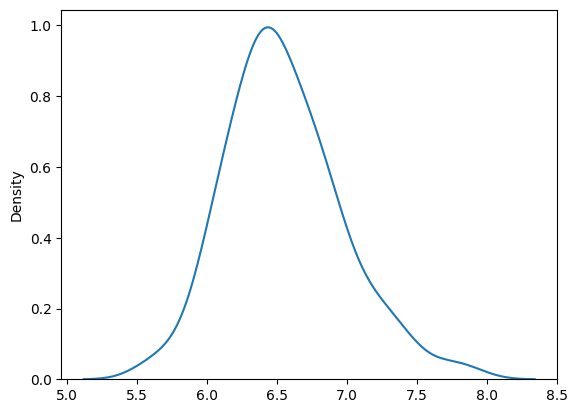

In [150]:
sns.kdeplot(data=sampling_means)

In [151]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.433917734327312 - 6.665980904314961
